1.	Import the required Python libraries (pandas, numpy, matplotlib, seaborn) and load the dataset into a DataFrame.

In [1]:
import pandas as pd

In [2]:
data=pd.read_csv("tastybite_food_orders.csv")

2.	Display the first five records, the shape, and the info of the dataset. Check for duplicate records and missing values, and clean the dataset by handling duplicates and missing values using appropriate techniques.

In [3]:
data.head()

,OrderID,CustomerName,Category,Dish,Price,Quantity,OrderDate,Location,PaymentMethod,Rating
0,5250,Ananya Das,South Indian,Uttapam,92.00,3.0,2025-02-25,Delhi-Delhi,Debit Card,5.0
1,5228,Amit Chandran,Chinese,Spring Rolls,131.29,4.0,2025-04-15,Coimbatore-Tamil Nadu,Net Banking,NaN
2,5278,Saanvi Chandran,Desserts,Gulab Jamun,271.85,1.0,2025-11-10,Kozhikode-Kerala,UPI,3.0
3,5046,Reyansh Iyer,South Indian,Filter Coffee Combo,208.06,1.0,2025-04-27,Kochi-Kerala,UPI,5.0
4,5128,Aarav Singh,South Indian,Masala Dosa,NaN,5.0,2025-05-05,Mysuru-Karnataka,Debit Card,1.0


In [4]:
data.shape

(315, 10)

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 315 entries, 0 to 314
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   OrderID        315 non-null    int64  
 1   CustomerName   310 non-null    object 
 2   Category       315 non-null    object 
 3   Dish           315 non-null    object 
 4   Price          303 non-null    float64
 5   Quantity       305 non-null    float64
 6   OrderDate      315 non-null    object 
 7   Location       309 non-null    object 
 8   PaymentMethod  307 non-null    object 
 9   Rating         295 non-null    float64
dtypes: float64(3), int64(1), object(6)
memory usage: 24.7+ KB


In [6]:
data.duplicated().sum()

10

In [7]:
data=data.drop_duplicates()

In [8]:
data.duplicated().sum()

0

In [9]:
data.isnull().sum()

OrderID           0
CustomerName      5
Category          0
Dish              0
Price            12
Quantity         10
OrderDate         0
Location          6
PaymentMethod     8
Rating           20
dtype: int64

In [10]:
data['Price']=data['Price'].fillna(data.groupby('Category')['Price'].transform('mean'))

In [11]:
data.isnull().sum()

OrderID           0
CustomerName      5
Category          0
Dish              0
Price             0
Quantity         10
OrderDate         0
Location          6
PaymentMethod     8
Rating           20
dtype: int64

In [12]:
data['Quantity']=data['Quantity'].fillna(data.groupby('Category')['Quantity'].transform('mean'))

In [13]:
data.isnull().sum()

OrderID           0
CustomerName      5
Category          0
Dish              0
Price             0
Quantity          0
OrderDate         0
Location          6
PaymentMethod     8
Rating           20
dtype: int64

In [14]:
data['PaymentMethod'].mode()

0    UPI
Name: PaymentMethod, dtype: object

In [15]:
data['PaymentMethod']=data['PaymentMethod'].fillna("UPI")

In [16]:
data.isnull().sum()

OrderID           0
CustomerName      5
Category          0
Dish              0
Price             0
Quantity          0
OrderDate         0
Location          6
PaymentMethod     0
Rating           20
dtype: int64

In [17]:
data['CustomerName']=data['CustomerName'].fillna("Unknown")

In [18]:
data.isnull().sum()

OrderID           0
CustomerName      0
Category          0
Dish              0
Price             0
Quantity          0
OrderDate         0
Location          6
PaymentMethod     0
Rating           20
dtype: int64

In [19]:
data['Rating']=data['Rating'].fillna(data['Rating'].mean())

3.	Split the Location column into separate City and State columns. 

In [20]:
data[['City','State']]=data['Location'].str.split('-',expand=True)

In [21]:
data['City']=data['City'].fillna("Unknown")
data['State']=data['State'].fillna("Unknown")

In [22]:
data=data.drop('Location',axis=1)

In [23]:
data.isnull().sum()

OrderID          0
CustomerName     0
Category         0
Dish             0
Price            0
Quantity         0
OrderDate        0
PaymentMethod    0
Rating           0
City             0
State            0
dtype: int64

4.	Create a new column named Revenue by calculating the total value generated from each order (Price x Quantity)

In [24]:
data.columns

Index(['OrderID', 'CustomerName', 'Category', 'Dish', 'Price', 'Quantity',
       'OrderDate', 'PaymentMethod', 'Rating', 'City', 'State'],
      dtype='object')

In [25]:
data["Revenue"]=data['Price']*data['Quantity']

5.	Create a new column named Rating_Status by classifying customer ratings as Good, Average, or Poor

In [26]:
Rating_Status=[]
for x in data['Rating']:
    if x>3:
        Rating_Status.append("Good")
    elif x==3:
        Rating_Status.append("Average")
    else:
        Rating_Status.append("Poor")


In [27]:
data['Rating_Status']=Rating_Status

6.	Create a new column named Price_Category by classifying dishes as Low, Medium, or High based on their price.

In [28]:
data['Price'].mean()

252.3720508589111

In [29]:
Price_Category=[]
for x in data['Price']:
    if x<250:
        Price_Category.append("Low")
    elif x>260:
        Price_Category.append("High")
    else:
        Price_Category.append("Medium")


In [30]:
data['Price_Category']=Price_Category

In [31]:
data

,OrderID,CustomerName,Category,Dish,Price,Quantity,OrderDate,PaymentMethod,Rating,City,State,Revenue,Rating_Status,Price_Category
0,5250,Ananya Das,South Indian,Uttapam,92.000000,3.0,2025-02-25,Debit Card,5.000000,Delhi,Delhi,276.000000,Good,Low
1,5228,Amit Chandran,Chinese,Spring Rolls,131.290000,4.0,2025-04-15,Net Banking,3.364912,Coimbatore,Tamil Nadu,525.160000,Good,Low
2,5278,Saanvi Chandran,Desserts,Gulab Jamun,271.850000,1.0,2025-11-10,UPI,3.000000,Kozhikode,Kerala,271.850000,Average,High
3,5046,Reyansh Iyer,South Indian,Filter Coffee Combo,208.060000,1.0,2025-04-27,UPI,5.000000,Kochi,Kerala,208.060000,Good,Low
4,5128,Aarav Singh,South Indian,Masala Dosa,159.112456,5.0,2025-05-05,Debit Card,1.000000,Mysuru,Karnataka,795.562281,Poor,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
309,5059,Diya Thomas,Italian,Farmhouse Pizza,601.380000,5.0,2025-04-03,Cash on Delivery,4.000000,Delhi,Delhi,3006.900000,Good,High
311,5088,Sanjay Krishnan,Desserts,Rasmalai,121.540000,2.0,2025-06-23,Cash on Delivery,5.000000,Mysuru,Karnataka,243.080000,Good,Low
312,5198,Unknown,Chinese,Manchurian,243.881739,6.0,2025-02-28,UPI,3.364912,Bengaluru,Karnataka,1463.290435,Good,Low
313,5175,Krishna Joseph,Fast Food,Cheese Sandwich,290.060000,1.0,2025-09-17,Cash on Delivery,5.000000,Coimbatore,Tamil Nadu,290.060000,Good,High


7.	Display the names of customers who ordered more than four items in a single order.

In [32]:
data['CustomerName'][data['Quantity']>4]

4        Aarav Singh
6       Karan Joseph
8       Arjun Mathew
9            Ira Das
14     Saanvi Joseph
           ...      
288     Rahul Mathew
297         Ira Shah
308       Sneha Shah
309      Diya Thomas
312          Unknown
Name: CustomerName, Length: 80, dtype: object

8.	Analyse the dataset by displaying the number of dishes available in each cuisine category, the number of orders placed using each payment method, and the number of customers from each state.

In [33]:
data.columns

Index(['OrderID', 'CustomerName', 'Category', 'Dish', 'Price', 'Quantity',
       'OrderDate', 'PaymentMethod', 'Rating', 'City', 'State', 'Revenue',
       'Rating_Status', 'Price_Category'],
      dtype='object')

In [34]:
data.groupby(['Category'])['Dish'].count()

Category
Chinese         48
Desserts        44
Fast Food       38
Italian         57
North Indian    57
South Indian    61
Name: Dish, dtype: int64

In [35]:
data.groupby(['PaymentMethod'])['OrderID'].count()

PaymentMethod
Cash on Delivery    55
Credit Card         53
Debit Card          62
Net Banking         60
UPI                 75
Name: OrderID, dtype: int64

In [36]:
data.groupby(['State'])['CustomerName'].count()

State
Delhi            16
Gujarat          15
Karnataka        49
Kerala           77
Maharashtra      37
Rajasthan        26
Tamil Nadu       35
Telangana        21
Unknown           6
Uttar Pradesh    23
Name: CustomerName, dtype: int64

9.	Calculate the total revenue generated by each cuisine category, the average customer rating for each payment method, the total quantity sold in each category, and the revenue generated by each category for every payment method

In [37]:
data.groupby(['Category'])['Revenue'].sum()

Category
Chinese         38765.253004
Desserts        23204.035581
Fast Food       27732.534324
Italian         82239.721650
North Indian    56850.085357
South Indian    29976.092289
Name: Revenue, dtype: float64

In [38]:
data.columns

Index(['OrderID', 'CustomerName', 'Category', 'Dish', 'Price', 'Quantity',
       'OrderDate', 'PaymentMethod', 'Rating', 'City', 'State', 'Revenue',
       'Rating_Status', 'Price_Category'],
      dtype='object')

In [39]:
data.groupby(['PaymentMethod'])['Rating'].mean()

PaymentMethod
Cash on Delivery    3.406635
Credit Card         3.171599
Debit Card          3.324109
Net Banking         3.275906
UPI                 3.575860
Name: Rating, dtype: float64

In [40]:
data.groupby(['Category'])['Quantity'].sum()

Category
Chinese         154.909091
Desserts        133.023256
Fast Food       127.351351
Italian         200.018182
North Indian    199.500000
South Indian    186.050000
Name: Quantity, dtype: float64

In [41]:
data.groupby(['PaymentMethod','Category'])['Revenue'].sum()

PaymentMethod     Category    
Cash on Delivery  Chinese          5131.780000
                  Desserts         4877.860000
                  Fast Food        4443.770000
                  Italian         17002.705849
                  North Indian     8531.420357
                  South Indian     5628.320000
Credit Card       Chinese          6997.530000
                  Desserts         4147.070000
                  Fast Food        5790.920000
                  Italian         12432.730000
                  North Indian    13224.105000
                  South Indian     4270.792281
Debit Card        Chinese          9955.353182
                  Desserts         1576.320000
                  Fast Food        7777.044324
                  Italian         18753.669249
                  North Indian     9610.150000
                  South Indian     8479.437018
Net Banking       Chinese          6825.250000
                  Desserts         7033.345581
                  Fast Food  

10. Create a Histogram to analyse the distribution of dish prices.

In [42]:
import matplotlib.pyplot as plt

In [43]:
total=data.groupby('Dish')['Price'].sum()

Text(0, 0.5, 'Price')

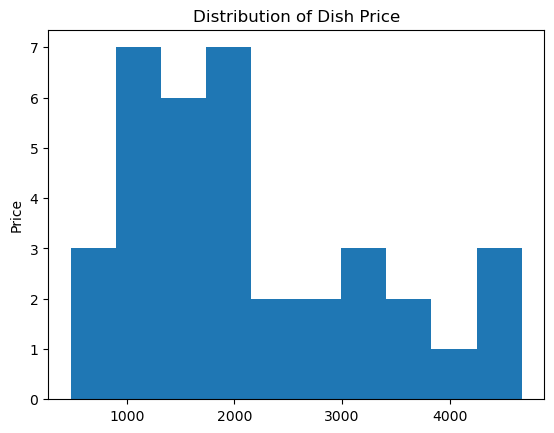

In [44]:
total.plot(kind='hist')
plt.title('Distribution of Dish Price')
plt.ylabel('Price')

11.	Create a Bar Chart to compare the total revenue generated by each cuisine category.

In [45]:
total2=data.groupby('Category')['Revenue'].sum()

Text(0, 0.5, 'Revenue')

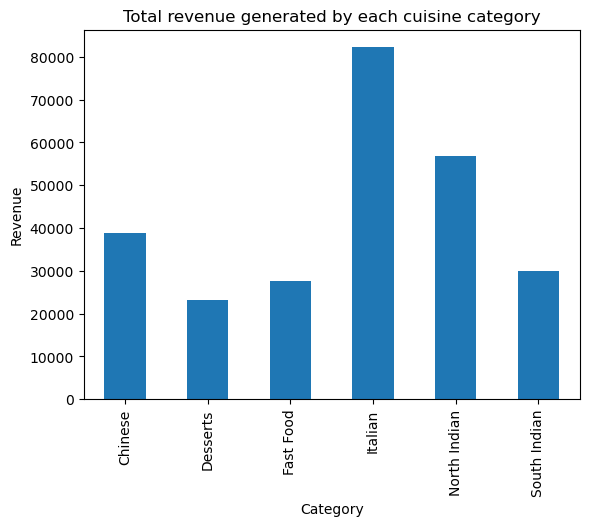

In [46]:
total2.plot(kind='bar')
plt.title('Total revenue generated by each cuisine category')
plt.ylabel('Revenue')


12.	Create a Pie Chart to display the percentage distribution of different payment methods used by customers.

In [48]:
total3=data.groupby('PaymentMethod')['CustomerName'].count()

Text(0, 0.5, '')

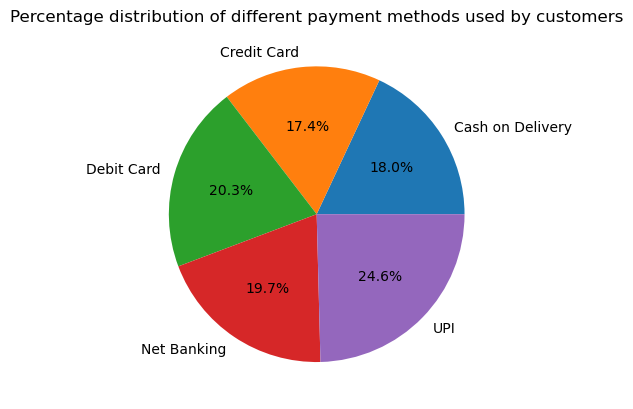

In [49]:
total3.plot(kind='pie',autopct="%1.1f%%")
plt.title("Percentage distribution of different payment methods used by customers")
plt.ylabel("")

13.	Create a Box Plot to compare the price distribution across different cuisine categories. 

In [50]:
import seaborn as sns

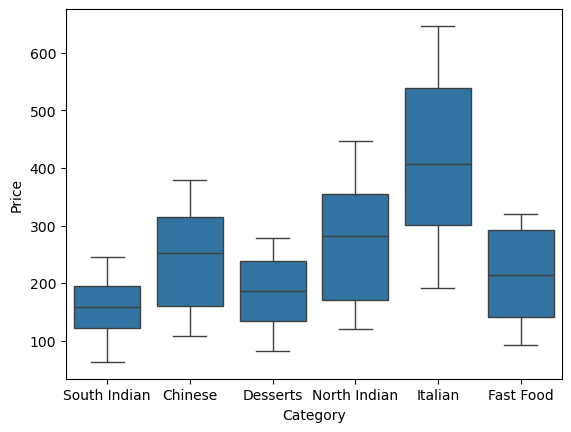

In [51]:
sns.boxplot(data=data,x='Category',y='Price')
plt.savefig('price_boxplot.png', bbox_inches='tight')

14.	Create a Line Chart to analyse the monthly revenue trend.

In [52]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 305 entries, 0 to 314
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   OrderID         305 non-null    int64  
 1   CustomerName    305 non-null    object 
 2   Category        305 non-null    object 
 3   Dish            305 non-null    object 
 4   Price           305 non-null    float64
 5   Quantity        305 non-null    float64
 6   OrderDate       305 non-null    object 
 7   PaymentMethod   305 non-null    object 
 8   Rating          305 non-null    float64
 9   City            305 non-null    object 
 10  State           305 non-null    object 
 11  Revenue         305 non-null    float64
 12  Rating_Status   305 non-null    object 
 13  Price_Category  305 non-null    object 
dtypes: float64(4), int64(1), object(9)
memory usage: 35.7+ KB


In [53]:
data.columns

Index(['OrderID', 'CustomerName', 'Category', 'Dish', 'Price', 'Quantity',
       'OrderDate', 'PaymentMethod', 'Rating', 'City', 'State', 'Revenue',
       'Rating_Status', 'Price_Category'],
      dtype='object')

In [54]:
data['OrderDate']=pd.to_datetime(data['OrderDate'],format="%Y-%m-%d")

In [55]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 305 entries, 0 to 314
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   OrderID         305 non-null    int64         
 1   CustomerName    305 non-null    object        
 2   Category        305 non-null    object        
 3   Dish            305 non-null    object        
 4   Price           305 non-null    float64       
 5   Quantity        305 non-null    float64       
 6   OrderDate       305 non-null    datetime64[ns]
 7   PaymentMethod   305 non-null    object        
 8   Rating          305 non-null    float64       
 9   City            305 non-null    object        
 10  State           305 non-null    object        
 11  Revenue         305 non-null    float64       
 12  Rating_Status   305 non-null    object        
 13  Price_Category  305 non-null    object        
dtypes: datetime64[ns](1), float64(4), int64(1), object(8)
memory us

In [56]:
data['Month']=data['OrderDate'].dt.to_period('M')

In [57]:
data

,OrderID,CustomerName,Category,Dish,Price,Quantity,OrderDate,PaymentMethod,Rating,City,State,Revenue,Rating_Status,Price_Category,Month
0,5250,Ananya Das,South Indian,Uttapam,92.000000,3.0,2025-02-25,Debit Card,5.000000,Delhi,Delhi,276.000000,Good,Low,2025-02
1,5228,Amit Chandran,Chinese,Spring Rolls,131.290000,4.0,2025-04-15,Net Banking,3.364912,Coimbatore,Tamil Nadu,525.160000,Good,Low,2025-04
2,5278,Saanvi Chandran,Desserts,Gulab Jamun,271.850000,1.0,2025-11-10,UPI,3.000000,Kozhikode,Kerala,271.850000,Average,High,2025-11
3,5046,Reyansh Iyer,South Indian,Filter Coffee Combo,208.060000,1.0,2025-04-27,UPI,5.000000,Kochi,Kerala,208.060000,Good,Low,2025-04
4,5128,Aarav Singh,South Indian,Masala Dosa,159.112456,5.0,2025-05-05,Debit Card,1.000000,Mysuru,Karnataka,795.562281,Poor,Low,2025-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
309,5059,Diya Thomas,Italian,Farmhouse Pizza,601.380000,5.0,2025-04-03,Cash on Delivery,4.000000,Delhi,Delhi,3006.900000,Good,High,2025-04
311,5088,Sanjay Krishnan,Desserts,Rasmalai,121.540000,2.0,2025-06-23,Cash on Delivery,5.000000,Mysuru,Karnataka,243.080000,Good,Low,2025-06
312,5198,Unknown,Chinese,Manchurian,243.881739,6.0,2025-02-28,UPI,3.364912,Bengaluru,Karnataka,1463.290435,Good,Low,2025-02
313,5175,Krishna Joseph,Fast Food,Cheese Sandwich,290.060000,1.0,2025-09-17,Cash on Delivery,5.000000,Coimbatore,Tamil Nadu,290.060000,Good,High,2025-09


In [58]:
Total5=data.groupby('Month')['Revenue'].sum()

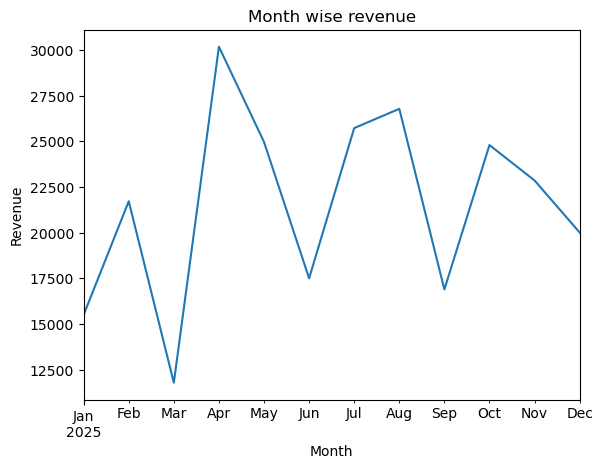

In [73]:
Total5.plot(kind='line')
plt.ylabel('Revenue')
plt.title('Month wise revenue')
plt.ticklabel_format(style='plain',axis='y')
plt.savefig('Linechart.png', bbox_inches='tight') 
plt.show()

15.	Create a Scatter Plot to examine the relationship between Quantity and Price. 

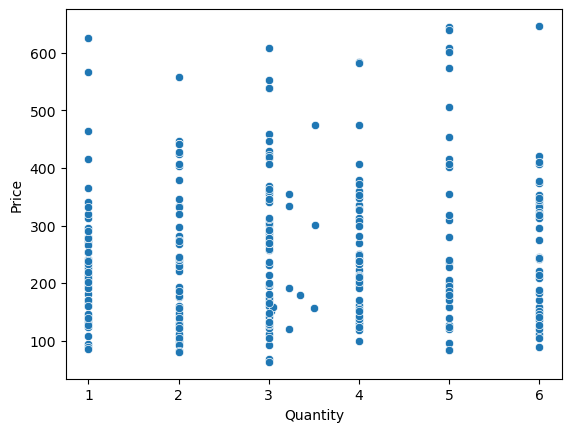

In [60]:
sns.scatterplot(data=data,x="Quantity",y="Price")
plt.savefig('correlation_heatmap.png', bbox_inches='tight')

16.	Create a Heatmap to analyse the correlation among Price, Quantity, Rating, and Revenue. 

In [61]:
df=data[['Price','Quantity','Rating','Revenue']]

In [62]:
df.corr()

,Price,Quantity,Rating,Revenue
Price,1.000000,0.098954,0.127254,0.726194
Quantity,0.098954,1.000000,-0.142834,0.687098
Rating,0.127254,-0.142834,1.000000,0.013138
Revenue,0.726194,0.687098,0.013138,1.000000


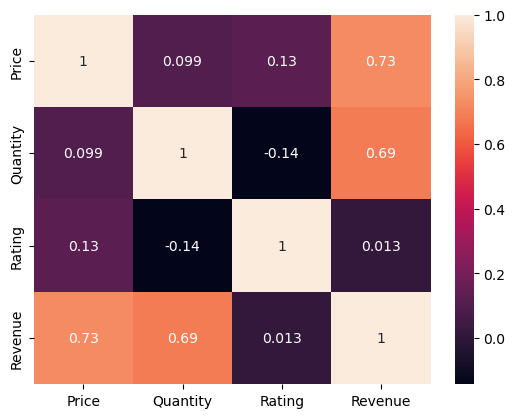

In [63]:
sns.heatmap(df.corr(),annot=True)
plt.savefig('correlation_heatmap.png', bbox_inches='tight')

17.	Create a Violin Plot to analyse the distribution of customer ratings across different cuisine categories.

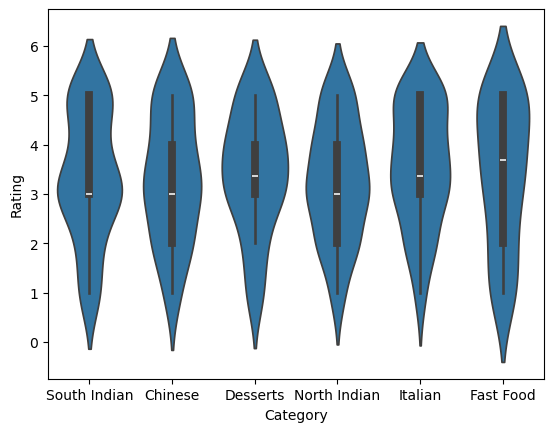

In [64]:
sns.violinplot(data=data,x='Category',y='Rating')
plt.savefig('rating_violin_plot.png', bbox_inches='tight') 

18.	Create a Pair Plot to compare the relationships among Price, Quantity, and Rating. 

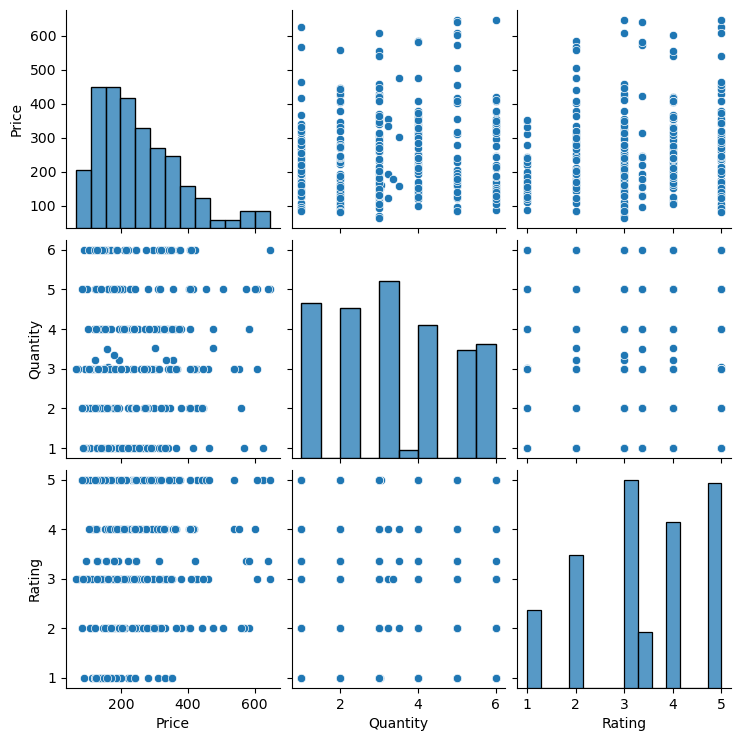

In [65]:
sns.pairplot(df[['Price', 'Quantity', 'Rating']])

19.	Create a Stacked Bar Chart to compare the number of orders placed through different payment methods for each cuisine category.

In [66]:
ad=data.groupby(['PaymentMethod','Category'])['OrderID'].count().unstack()

<Axes: xlabel='PaymentMethod'>

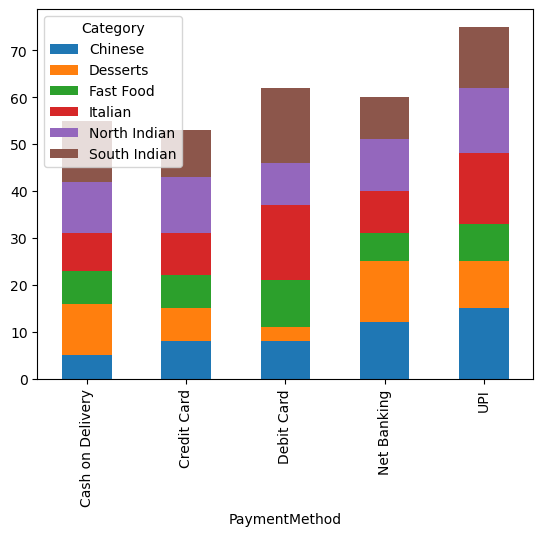

In [67]:
ad.plot(kind='bar',stacked=True)

20.	Create a Regression Plot to examine the trend between Quantity and Price. 

<Axes: xlabel='Quantity', ylabel='Price'>

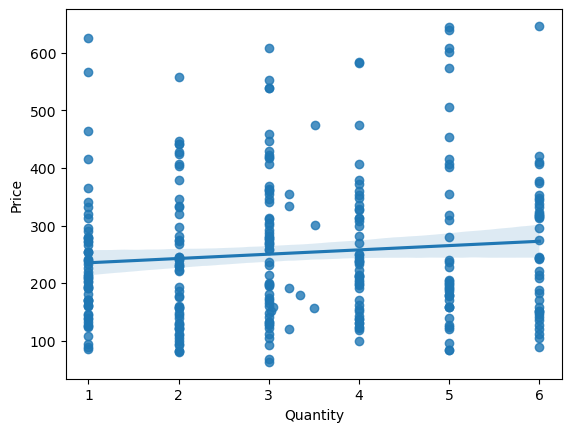

In [68]:
sns.regplot(data=data,x='Quantity',y='Price')

21.	Create a subplot containing a Histogram, Bar Chart, Box Plot, and Line Chart in a single figure. 

In [69]:
import matplotlib.pyplot as plt

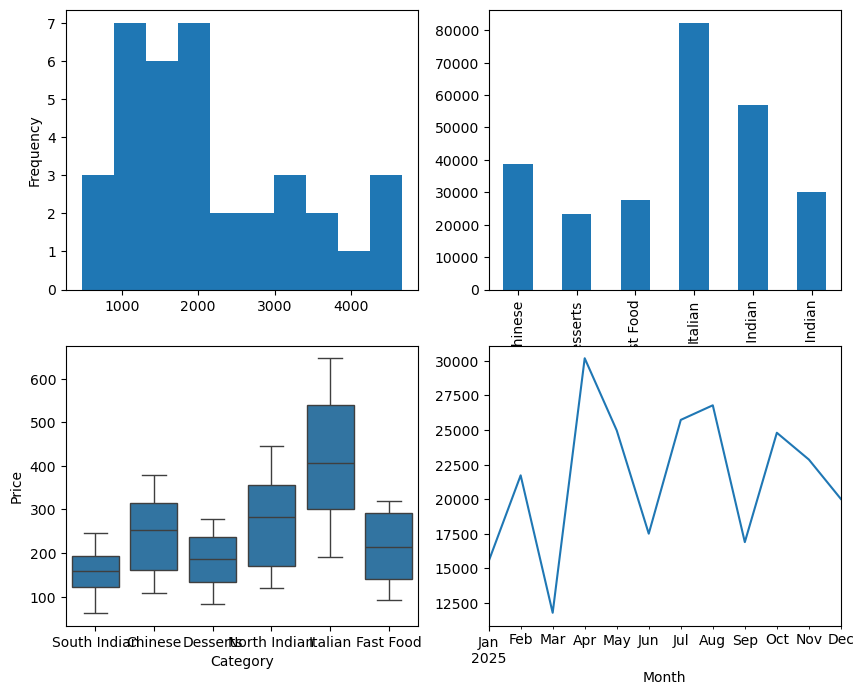

In [70]:
plt.figure(figsize=(10,8))
plt.subplot(2,2,1)
total.plot(kind="hist")
plt.subplot(2,2,2)
total2.plot(kind='bar')
plt.subplot(2,2,3)
sns.boxplot(data=data,x='Category',y='Price')
plt.subplot(2,2,4)
Total5.plot(kind='line')
plt.show()

22.	Create a Dual Axis Chart to compare Monthly Revenue and Monthly Quantity Sold in a single visualization.

In [71]:
data.columns

Index(['OrderID', 'CustomerName', 'Category', 'Dish', 'Price', 'Quantity',
       'OrderDate', 'PaymentMethod', 'Rating', 'City', 'State', 'Revenue',
       'Rating_Status', 'Price_Category', 'Month'],
      dtype='object')

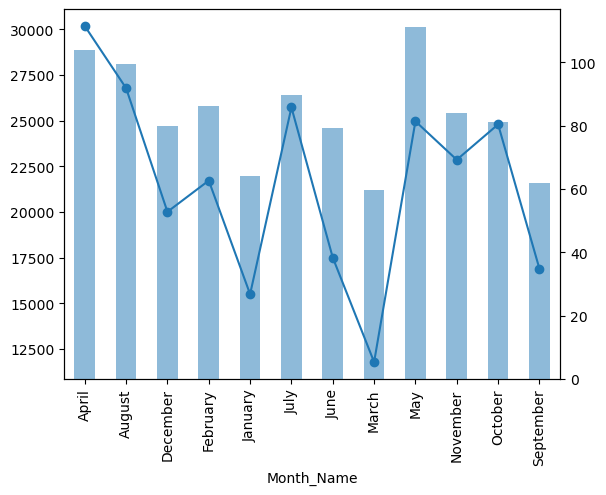

In [72]:
data['Month']
data["Month_Name"]=data["OrderDate"].dt.month_name()
data["Month_Name"]
d=data.groupby('Month_Name')[['Revenue','Quantity']].sum()
ax=d['Revenue'].plot(kind='line',marker="o")
d['Quantity'].plot(kind='bar',secondary_y=True,alpha=0.5,ax=ax)
plt.savefig('monthly_revenue_trend.png', bbox_inches='tight')